# Member 4 — ML Modelling & Evaluation
## Hybrid Multimodal AI Framework for Non-Invasive Anemia Detection

This notebook provides an end-to-end walkthrough of the Member 4 ML pipeline:
- Dataset audit summary
- Handcrafted feature extraction
- Hb regression baselines and XGBoost
- Anemia classification
- Model comparisons (handcrafted vs Member 3 CNN results)
- Evaluation plots and metrics

In [1]:
import sys
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

# Locate the project root whether Jupyter starts here or in the notebook folder.
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (_here, *_here.parents)
                     if (p / 'member4_ml_modelling' / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter from the project root or a subfolder.')
SRC = PROJECT_ROOT / 'member4_ml_modelling' / 'src'
sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from config import *
from data_loading import load_eye_splits, load_nail_splits, load_full_splits, load_palm_splits
from feature_extraction import extract_feature_matrix, get_feature_columns
from evaluation import regression_metrics, classification_metrics
from plotting import (
    plot_actual_vs_predicted, plot_residuals, plot_regression_comparison,
    plot_feature_importance, plot_confusion_matrix, plot_roc_curve,
    plot_classification_comparison
)

print('Imports OK')
print(f'Project root: {PROJECT_ROOT}')


Imports OK
Project root: C:\Users\nethr\Downloads\Anemia_ML_Project


## 1. Dataset Audit Summary

In [2]:
feat_dir = M4_DIR / 'outputs' / 'features'
feature_files = {
    'Eye/Conjunctiva': ('eye_handcrafted.parquet', 'Lab-measured Hb reported in source paper as g/dL; inherited thresholds, 19 participants over 65'),
    'Nail (Figshare)': ('nail_handcrafted.parquet', 'Measured Hb; inherited <11 g/dL exploratory threshold'),
    'Full-hand (Figshare)': ('full_handcrafted.parquet', 'Measured Hb; inherited <11 g/dL exploratory threshold'),
    'Palm': ('palm_handcrafted.parquet', 'No measured Hb; folder-derived class only'),
}
_audit_rows = []
for name, (filename, label_source) in feature_files.items():
    path = feat_dir / filename
    if path.exists():
        data = pd.read_parquet(path)
        _audit_rows.append({'Dataset': name, 'Model samples': len(data),
                            'Groups': data['participant_id'].nunique() if 'participant_id' in data else 'n/a',
                            'Hb available': 'Yes' if data.get('hb_g_dl', pd.Series(dtype=float)).notna().any() else 'No',
                            'Label provenance': label_source})
audit_df = pd.DataFrame(_audit_rows)
print('Current modeling data summary (loaded from saved feature caches)')
print(audit_df.to_string(index=False))


Current modeling data summary (loaded from saved feature caches)
             Dataset  Model samples  Groups Hb available                                                                                Label provenance
     Eye/Conjunctiva            610     202          Yes Lab-measured Hb reported in source paper as g/dL; inherited thresholds, 19 participants over 65
     Nail (Figshare)            719     250          Yes                                           Measured Hb; inherited <11 g/dL exploratory threshold
Full-hand (Figshare)            250     250          Yes                                           Measured Hb; inherited <11 g/dL exploratory threshold
                Palm           2056     514           No                                                       No measured Hb; folder-derived class only


## 2. Load Existing Feature Matrices (from Pipeline)

In [3]:
feat_dir = M4_DIR / 'outputs' / 'features'

eye_feat  = pd.read_parquet(feat_dir / 'eye_handcrafted.parquet') if (feat_dir / 'eye_handcrafted.parquet').exists() else None
nail_feat = pd.read_parquet(feat_dir / 'nail_handcrafted.parquet') if (feat_dir / 'nail_handcrafted.parquet').exists() else None
full_feat = pd.read_parquet(feat_dir / 'full_handcrafted.parquet') if (feat_dir / 'full_handcrafted.parquet').exists() else None
palm_feat = pd.read_parquet(feat_dir / 'palm_handcrafted.parquet') if (feat_dir / 'palm_handcrafted.parquet').exists() else None

for name, df in [('Eye', eye_feat), ('Nail', nail_feat), ('Full', full_feat), ('Palm', palm_feat)]:
    if df is not None:
        print(f'{name}: {df.shape[0]} samples x {df.shape[1]} columns')
    else:
        print(f'{name}: not yet computed — run run_pipeline.py first')

Eye: 610 samples x 144 columns
Nail: 719 samples x 146 columns
Full: 250 samples x 146 columns
Palm: 2056 samples x 142 columns


## 3. Hb Distribution (Eye Dataset)

Hb stats: mean=12.62, std=2.39, min=7.0, max=17.4 g/dL
Label counts: {0: 338, 1: 272}


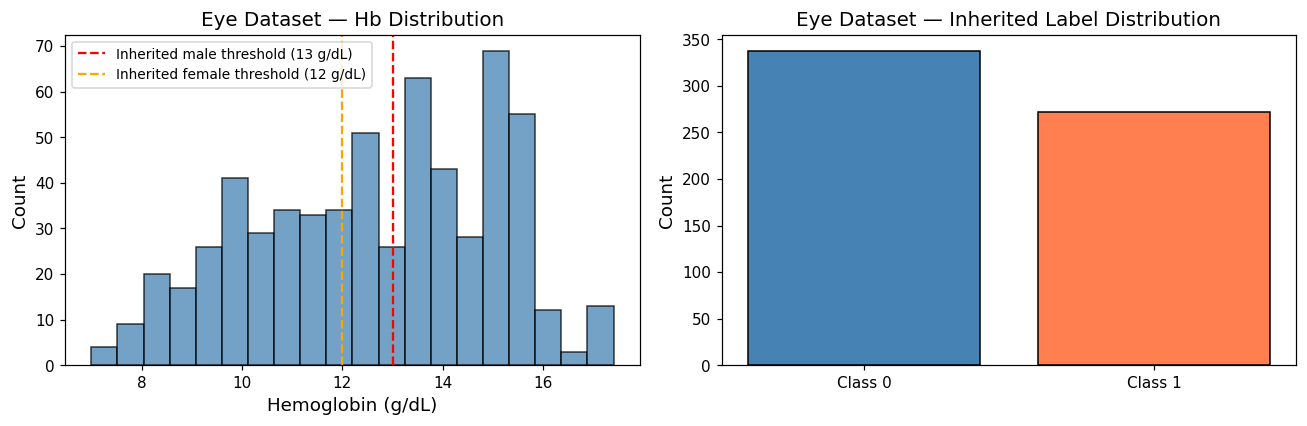

In [4]:
if eye_feat is not None and 'hb_g_dl' in eye_feat.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    hb = eye_feat['hb_g_dl'].dropna()
    axes[0].hist(hb, bins=20, edgecolor='k', alpha=0.75, color='steelblue')
    axes[0].axvline(13, color='r', linestyle='--', label='Inherited male threshold (13 g/dL)')
    axes[0].axvline(12, color='orange', linestyle='--', label='Inherited female threshold (12 g/dL)')
    axes[0].set_xlabel('Hemoglobin (g/dL)', fontsize=12)
    axes[0].set_ylabel('Count', fontsize=12)
    axes[0].set_title('Eye Dataset — Hb Distribution', fontsize=13)
    axes[0].legend(fontsize=9)
    label_counts = eye_feat['anemia_label'].value_counts()
    axes[1].bar(['Class 0', 'Class 1'], [label_counts.get(0, 0), label_counts.get(1, 0)],
                color=['steelblue', 'coral'], edgecolor='k')
    axes[1].set_title('Eye Dataset — Inherited Label Distribution', fontsize=13)
    axes[1].set_ylabel('Count', fontsize=12)
    plt.tight_layout()
    plt.savefig(str(OUT_PLOTS / 'eye_hb_distribution.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Hb stats: mean={hb.mean():.2f}, std={hb.std():.2f}, min={hb.min():.1f}, max={hb.max():.1f} g/dL')
    print(f'Label counts: {label_counts.to_dict()}')


## 4. Load and Display Metrics Summary

In [5]:
metrics_path = M4_DIR / 'outputs' / 'metrics' / 'all_metrics_summary.csv'
if metrics_path.exists():
    summary = pd.read_csv(metrics_path)
    print(f'Total experiments: {len(summary)}')
    
    # Regression results
    reg = summary[summary['task'] == 'regression'][['model', 'dataset', 'MAE_g/dL', 'RMSE_g/dL', 'R2', 'n_test', 'caveats']].copy()
    print('\n=== REGRESSION RESULTS ===')
    print(reg.to_string(index=False))
    
    # Classification results
    cls = summary[summary['task'] == 'classification'][['model', 'dataset', 'accuracy', 'f1_score', 'roc_auc', 'n_test', 'caveats']].copy()
    print('\n=== CLASSIFICATION RESULTS ===')
    print(cls.to_string(index=False))
else:
    print('Metrics not yet generated — run run_pipeline.py first')

Total experiments: 25

=== REGRESSION RESULTS ===
              model   dataset  MAE_g/dL  RMSE_g/dL      R2  n_test                                                                                                                                    caveats
       Dummy (mean)       Eye    2.5032     2.7684 -0.0002      89                                                                                                                                        NaN
      Random Forest       Eye    1.5165     2.0524  0.4502      89                                                                                                                                        NaN
        Extra Trees       Eye    1.4370     1.9832  0.4867      89                                                                                                                                        NaN
       Dummy (mean)      Nail    1.7437     2.3773 -0.0029     109                                                            

## 5. Member 3 CNN reference results (not row-matched after Eye deduplication)

The supplied Eye CNN prediction file has 92 rows without image or participant IDs. Member 4 now evaluates 89 unique Eye test images after exact-content deduplication. Treat these as separate aggregate references, not a paired model comparison.


In [6]:
# Re-score the supplied Member 3 aggregate reference; row-wise matching is unavailable.
m3_eye_pred_path = EYE_REG_PREDICTIONS_CSV
if m3_eye_pred_path.exists():
    m3_preds = pd.read_csv(m3_eye_pred_path)
    print(f'Member 3 Eye CNN prediction rows: {len(m3_preds)} (IDs absent)')
    m3_eye_metrics = regression_metrics(m3_preds['true_hb'], m3_preds['predicted_hb'])
    print(f"CNN reference: MAE={m3_eye_metrics['MAE_g/dL']:.4f} "
          f"RMSE={m3_eye_metrics['RMSE_g/dL']:.4f} R2={m3_eye_metrics['R2']:.4f}")


Member 3 Eye CNN prediction rows: 92 (IDs absent)
CNN reference: MAE=1.8578 RMSE=2.4230 R2=0.2202


In [7]:
# Plot Member 3's supplied predictions as a reference, not as a same-row comparison.
if m3_eye_pred_path.exists():
    m3_preds = pd.read_csv(m3_eye_pred_path)
    plot_actual_vs_predicted(
        m3_preds['true_hb'], m3_preds['predicted_hb'],
        title='Member 3 Eye CNN — Supplied Aggregate Reference',
        path=OUT_PLOTS / 'm3_eye_cnn_actual_vs_predicted.png'
    )
    print('Member 3 CNN reference plot saved')


  Plot saved → C:\Users\nethr\Downloads\Anemia_ML_Project\member4_ml_modelling\outputs\plots\m3_eye_cnn_actual_vs_predicted.png
Member 3 CNN reference plot saved


## 6. Leakage Verification

In [8]:
from data_loading import verify_no_participant_leakage, load_eye_splits, load_nail_splits

print('Verifying participant leakage on the current model rows...')
# Use deduplicated feature caches so this checks the same rows used by evaluation.
eye_df = (eye_feat[['participant_id', 'split']] if eye_feat is not None else
          load_eye_splits(EYE_SPLITS_CSV, EYE_PREPROCESSED_DIR))
ok1 = verify_no_participant_leakage(eye_df, 'Eye')

nail_df = (nail_feat[['participant_id', 'split']] if nail_feat is not None else
           load_nail_splits(NAIL_SPLITS_CSV, FIGSHARE_DIR))
ok2 = verify_no_participant_leakage(nail_df, 'Nail')

print(f'Eye modeling rows: {len(eye_df)}; leakage-free: {ok1}')
print(f'Nail modeling rows: {len(nail_df)}; leakage-free: {ok2}')

Verifying participant leakage on the current model rows...
  Eye: No participant leakage detected [OK]
  Nail: No participant leakage detected [OK]
Eye modeling rows: 610; leakage-free: True
Nail modeling rows: 719; leakage-free: True


## 7. Feature Importance (if available)

In [9]:
import pickle
model_path = M4_DIR / 'outputs' / 'models' / 'eye_handcrafted_regression.pkl'
if model_path.exists():
    with open(model_path, 'rb') as f:
        model_obj = pickle.load(f)
    rf = model_obj['rf']
    feat_cols = model_obj['feature_cols']
    importances = rf.feature_importances_
    top_idx = np.argsort(importances)[::-1][:10]
    print('Top 10 features (Eye RF Regression):')
    for i in top_idx:
        print(f'  {feat_cols[i]}: {importances[i]:.4f}')
else:
    print('Model not yet trained — run run_pipeline.py first')

Top 10 features (Eye RF Regression):
  paleness_index: 0.1312
  R_hist_13: 0.1245
  redness_ratio: 0.1051
  LAB_B_lab_std: 0.0404
  HSV_S_p90: 0.0312
  LAB_A_p75: 0.0300
  G_std: 0.0295
  R_hist_12: 0.0186
  LAB_B_lab_mean: 0.0153
  R_hist_10: 0.0140


## 8. Summary

### Implemented locally
- Handcrafted image feature extraction and conventional/XGBoost Hb regression for Eye, Nail, and Full-hand data.
- Exploratory classification for Eye, Figshare Nail, and Palm using the supplied labels.
- Exact duplicate handling, a Palm near-duplicate audit, held-out metrics, saved models, predictions, and plots.

### Findings and limitations
- Eye Hb is source-study lab-measured and reported in g/dL; inherited threshold labels are exploratory because 19 participants are over 65 and pregnancy/altitude/smoking context is unavailable.
- Figshare's inherited <11 g/dL label lacks age/sex context and is a low-Hb threshold experiment only.
- Palm has no Hb ground truth; its target comes from folder names and is not clinically verified.
- No paired participants across modalities; no fusion experiment is supported.
- Member 3 scratch-trained regression checkpoints were used to extract image-keyed 1,024-D embeddings for Eye and Nail. Separate XGBoost models on those embeddings did not beat handcrafted XGBoost on the same held-out images. No full-hand regression checkpoint exists.
- Results are academic research outputs, not diagnostic tools or replacements for laboratory CBC testing.
